# ARTI 403 – Image Processing
## Lab 7 (A) — Laplacian Filter

**Student name:** Ahmed Albuainain
**Student ID:** 2240006128
**Section:** 7MA1
**Date:** 26 October 2026

---

### Session Outcome
Write a program that implements fundamental image processing algorithms.

### Contents
| Part | Description |
|---|---|
| Part 0 | Environment check and the image |
| Part 1 | The Laplacian with a manually defined kernel |
| Part 2 | Why `img + laplacian_abs` overflows — and the fix |
| Part 3 | `f + abs(lap)` versus `f - lap`: which one actually sharpens |
| Part 4 | The same result using `cv2.Laplacian` |
| Part 5 | The 4-neighbour and 8-neighbour kernels compared |

---
## Part 0 — Environment check and the image

`moon.jpg` must sit in the same folder as this notebook (or in `images/`). The cell below
resolves either location, so the notebook runs without editing the path.

In [16]:
import os
import sys
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("OpenCV    :", cv2.__version__)

%matplotlib inline

Python    : 3.13.5
NumPy     : 2.3.5
OpenCV    : 5.0.0


In [17]:
import glob

os.makedirs("output", exist_ok=True)
SEARCH_DIRS = [".", "images", os.path.join("..", "images")]

def find_image(*names):
    """First of these filenames that exists in any search folder, else any image found."""
    for name in names:
        for d in SEARCH_DIRS:
            p = os.path.join(d, name)
            if os.path.exists(p):
                return p
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "*.jpg")) + glob.glob(os.path.join(d, "*.png")))
        if hits:
            return hits[0]
    raise FileNotFoundError("no image file found next to the notebook or in images/")


imgFile = find_image("moon.jpg", "Moon.jpg", "moon.png")
print("using:", os.path.abspath(imgFile))

img = cv2.imread(imgFile, 0)
print("shape:", img.shape, "| dtype:", img.dtype,
      "| range:", img.min(), "-", img.max(),
      "| mean:", round(float(img.mean()), 1))

using: c:\Users\ahmad\OneDrive\Desktop\im Labs\lab1\Lab 7\images\moon.jpg
shape: (438, 401) | dtype: uint8 | range: 0 - 255 | mean: 47.6


---
## Part 1 — The Laplacian with a manually defined kernel

The Laplacian is a **second-derivative** operator. Its kernel sums to zero, so it produces
nothing on flat regions and responds only where the intensity changes — at edges and fine
detail. That is what makes it an edge detector, and what makes it useful for sharpening.

Two points about the code below are worth noticing before running it.

**`cv2.CV_64F` rather than `-1`.** The Laplacian produces **negative** values wherever a pixel
is brighter than its neighbours. Asking for a `uint8` output would clip every one of them to
zero and silently throw away half the response.

**`convertScaleAbs`** then takes the absolute value and converts back to 8-bit, so that both
the positive and negative parts of the response become visible.

kernel:
 [[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]
sum of weights: 0.0  <- zero, so flat regions give no response


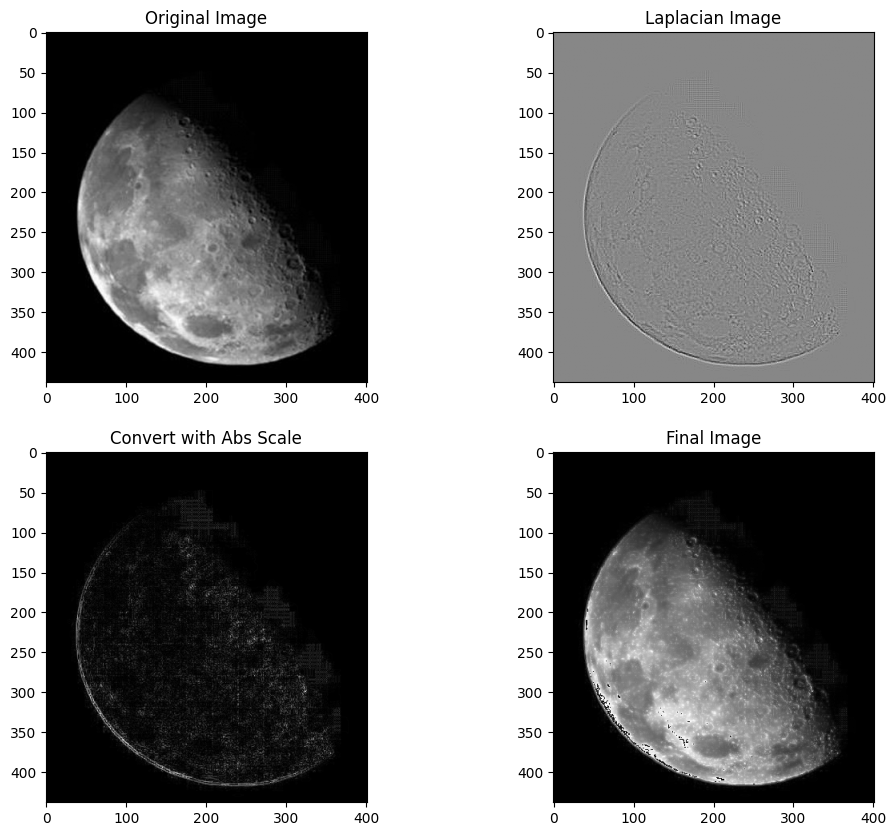

In [18]:
# ================ ( Laplacian Filter ) ===================

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

print("kernel:\n", manual_kernel)
print("sum of weights:", float(manual_kernel.sum()), " <- zero, so flat regions give no response")

# 3. Apply the filter using filter2D
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()

In [19]:
print("Laplacian (CV_64F) range :", round(float(laplacian_manual.min()), 1),
      "to", round(float(laplacian_manual.max()), 1), " <- negative values are preserved")
print("after convertScaleAbs    :", laplacian_abs.min(), "to", laplacian_abs.max(),
      " <- now unsigned 8-bit")
print("mean of the Laplacian    :", round(float(laplacian_manual.mean()), 4),
      " <- near zero, as a zero-sum kernel predicts")

Laplacian (CV_64F) range : -123.0 to 110.0  <- negative values are preserved
after convertScaleAbs    : 0 to 123  <- now unsigned 8-bit
mean of the Laplacian    : 0.0  <- near zero, as a zero-sum kernel predicts


---
## Part 2 — Why `img + laplacian_abs` overflows

Look closely at the fourth panel above. Scattered through the bright parts of the moon there
are **dark speckles** that are not in the original image. They are not noise in the photograph;
they are an arithmetic error.

`img` and `laplacian_abs` are both `uint8`, which can only hold 0–255. NumPy does **not** clip
when that range is exceeded — it **wraps around**. So `220 + 110` gives 330, and 330 mod 256 is
**74**: a bright pixel plus a strong edge response comes out dark.

This is the same `uint8` trap met in Lab 2 with image addition and in Lab 5 with the sharpening
mask. The cell below measures exactly how many pixels are affected.

In [20]:
true_sum = img.astype(np.int16) + laplacian_abs.astype(np.int16)
overflow = true_sum > 255

print("pixels whose true sum exceeds 255 :", int(overflow.sum()),
      f"({100 * overflow.mean():.2f}% of the image)")
print("largest true sum                  :", int(true_sum.max()))
print()

r, c = np.argwhere(overflow)[0]
print("a concrete example:")
print(f"  img[{r},{c}]           = {img[r, c]}")
print(f"  laplacian_abs[{r},{c}] = {laplacian_abs[r, c]}")
print(f"  true sum              = {int(true_sum[r, c])}")
print(f"  uint8 result          = {finalImage[r, c]}   <- wrapped around (mod 256)")

pixels whose true sum exceeds 255 : 541 (0.31% of the image)
largest true sum                  : 362

a concrete example:
  img[196,43]           = 194
  laplacian_abs[196,43] = 66
  true sum              = 260
  uint8 result          = 4   <- wrapped around (mod 256)


### The fix

`cv2.add` saturates instead of wrapping: anything above 255 becomes 255. `np.clip` on a wider
type does the same thing.

cv2.add and np.clip agree: True
largest difference from the wrapped version: 255  <- a full inversion where it happens


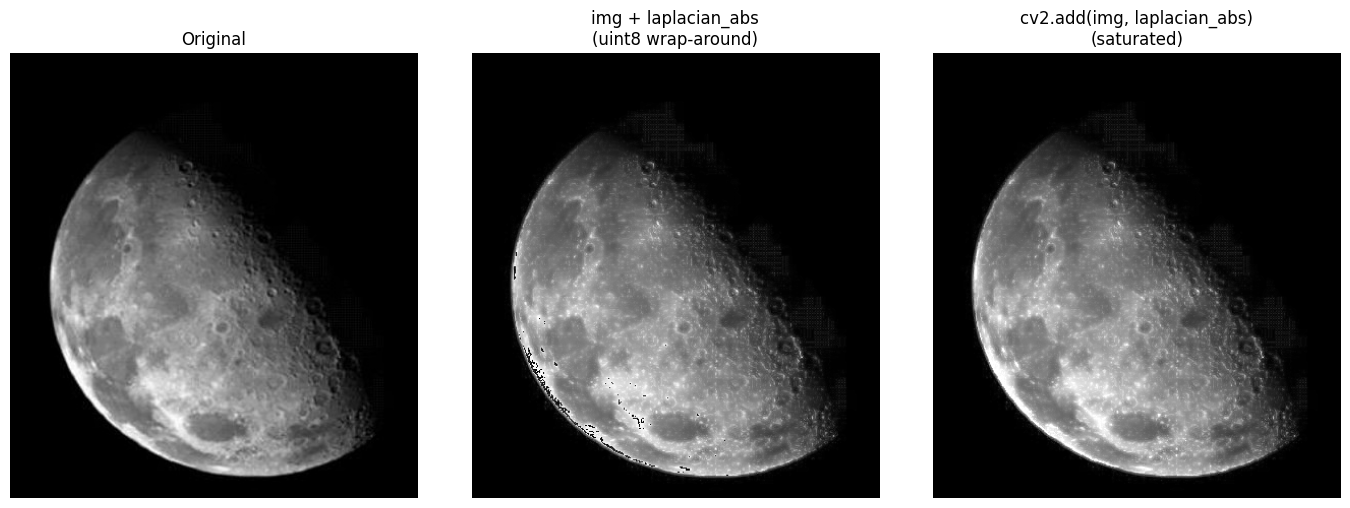

In [21]:
finalImage_saturated = cv2.add(img, laplacian_abs)
finalImage_clipped = np.clip(true_sum, 0, 255).astype(np.uint8)

print("cv2.add and np.clip agree:", np.array_equal(finalImage_saturated, finalImage_clipped))
print("largest difference from the wrapped version:",
      int(np.abs(finalImage.astype(np.int16)
                 - finalImage_saturated.astype(np.int16)).max()),
      " <- a full inversion where it happens")

plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(finalImage, cmap='gray')
plt.title('img + laplacian_abs\n(uint8 wrap-around)'), plt.axis('off')
plt.subplot(133), plt.imshow(finalImage_saturated, cmap='gray')
plt.title('cv2.add(img, laplacian_abs)\n(saturated)'), plt.axis('off')
plt.tight_layout()
plt.show()

---
## Part 3 — `f + abs(lap)` versus `f - lap`

There is a second question hidden in this code, separate from the overflow.

The kernel has a **negative centre**. At a bright point surrounded by darker pixels the
Laplacian output is therefore negative, which means the textbook sharpening formula is

$$g = f - \nabla^2 f$$

Subtracting a negative number raises the bright point; subtracting a positive one deepens the
dark point. Edges gain contrast **in both directions**.

Taking the absolute value first and adding, as the given code does, is a different operation:
it adds brightness at **every** edge regardless of which side is which. It does increase
apparent sharpness, but it also lightens the image overall and loses the symmetry. The cell
below measures both.

version                          mean      std
----------------------------------------------
original                        47.60    65.11
f + abs(lap)  (saturated)       51.66    68.57
f - lap       (textbook)        47.92    66.28

f + abs(lap) raises the mean by 4.1 levels — the whole image gets brighter
f - lap      changes the mean by 0.3 levels — brightness is essentially preserved


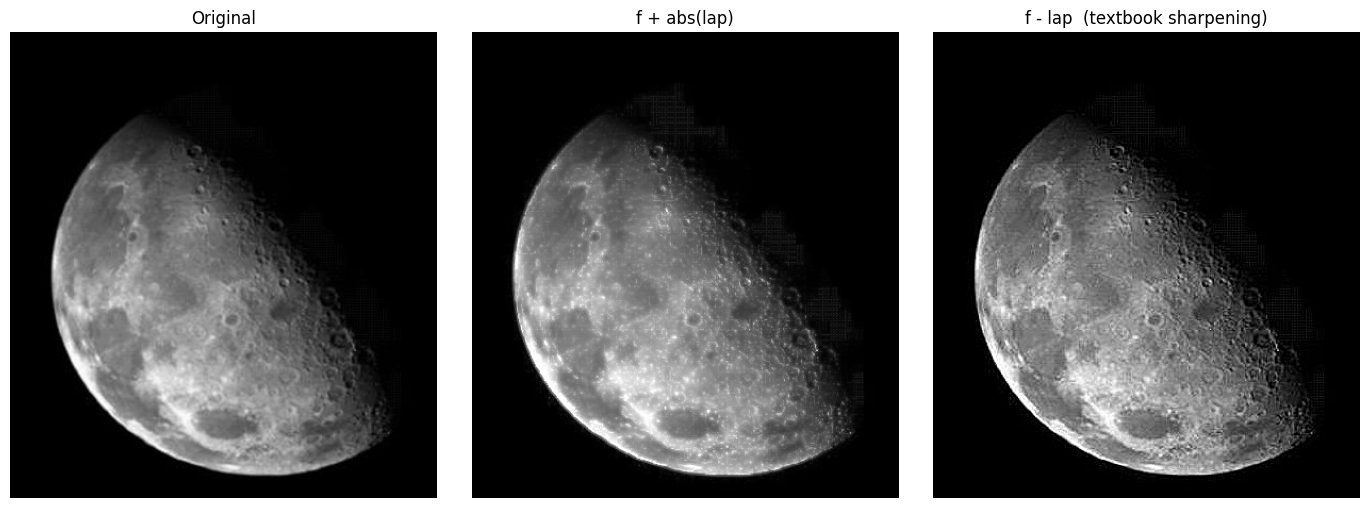

In [22]:
sharpened_subtract = np.clip(img.astype(np.float64) - laplacian_manual,
                             0, 255).astype(np.uint8)

print(f"{'version':<28}{'mean':>9}{'std':>9}")
print("-" * 46)
for name, im in [("original", img),
                 ("f + abs(lap)  (saturated)", finalImage_saturated),
                 ("f - lap       (textbook)", sharpened_subtract)]:
    print(f"{name:<28}{im.mean():>9.2f}{im.std():>9.2f}")

print()
print("f + abs(lap) raises the mean by",
      round(float(finalImage_saturated.mean() - img.mean()), 1),
      "levels — the whole image gets brighter")
print("f - lap      changes the mean by",
      round(float(sharpened_subtract.mean() - img.mean()), 1),
      "levels — brightness is essentially preserved")

plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(finalImage_saturated, cmap='gray')
plt.title('f + abs(lap)'), plt.axis('off')
plt.subplot(133), plt.imshow(sharpened_subtract, cmap='gray')
plt.title('f - lap  (textbook sharpening)'), plt.axis('off')
plt.tight_layout()
plt.show()

Both look sharper than the original, so neither is "wrong" as a demonstration. But
`f - lap` is the form given in the textbook, it keeps the average brightness, and it responds
symmetrically on the two sides of an edge. `f + abs(lap)` brightens the image as a side effect,
which is visible in the mean.

---
## Part 4 — The same result using `cv2.Laplacian`

`cv2.Laplacian` applies the same operator without the kernel having to be written out. The
`GaussianBlur` beforehand matters: the Laplacian responds to rapid change, and it cannot tell a
genuine edge from a noisy pixel, so a small blur stops it amplifying noise. The pair is known
as the **Laplacian of Gaussian**.

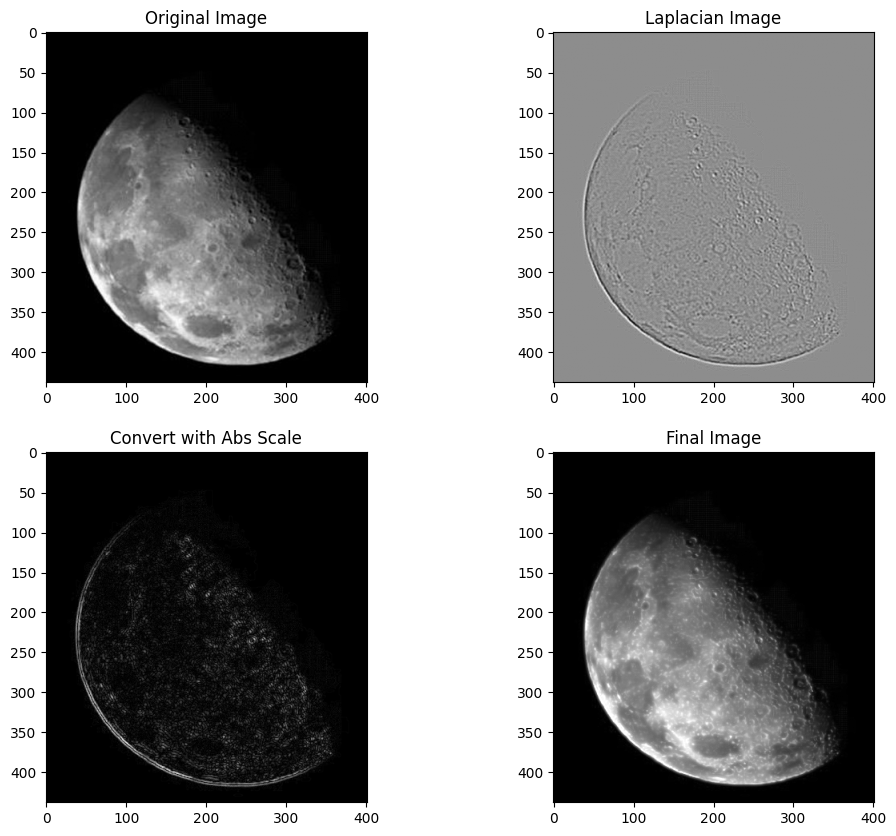

In [23]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and original Image  (saturating, to avoid the wrap-around of Part 2)
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()

### What the blur actually bought

Comparing the two Laplacian responses side by side shows the difference the blur made.

Laplacian without blur : range -123.0 to 110.0 | std 8.75
Laplacian after blur   : range -66.0 to 53.0 | std 5.15  <- weaker response, because the noise is gone


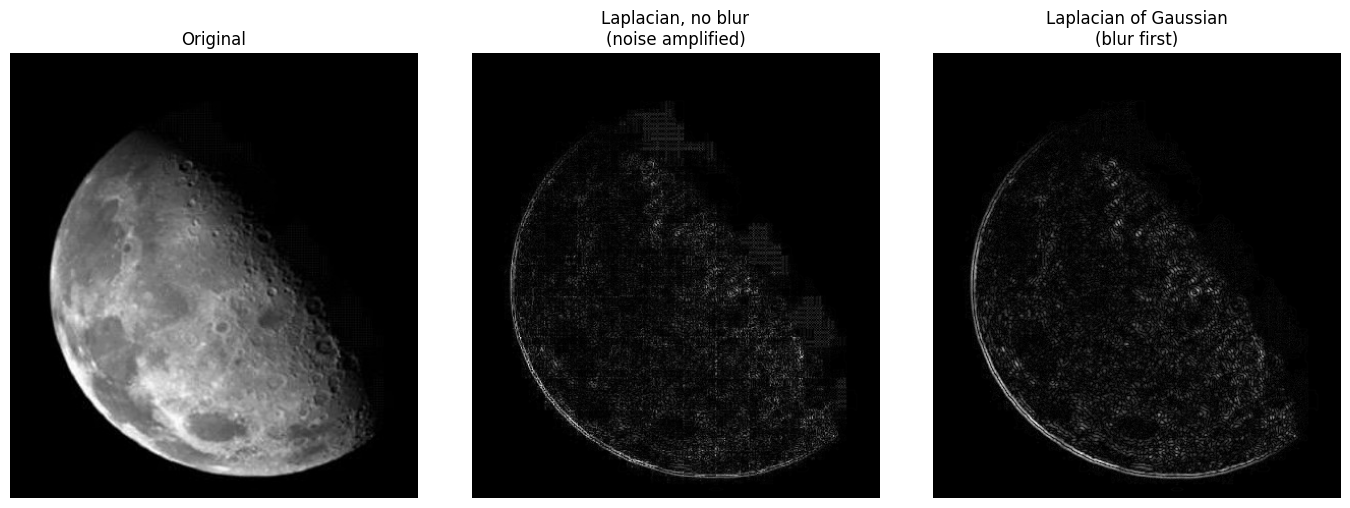

In [24]:
lap_noblur = cv2.Laplacian(img, cv2.CV_64F)

print("Laplacian without blur : range", round(float(lap_noblur.min()), 1),
      "to", round(float(lap_noblur.max()), 1),
      "| std", round(float(lap_noblur.std()), 2))
print("Laplacian after blur   : range", round(float(laplacian.min()), 1),
      "to", round(float(laplacian.max()), 1),
      "| std", round(float(laplacian.std()), 2),
      " <- weaker response, because the noise is gone")

plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(cv2.convertScaleAbs(lap_noblur), cmap='gray')
plt.title('Laplacian, no blur\n(noise amplified)'), plt.axis('off')
plt.subplot(133), plt.imshow(laplacian_8bit, cmap='gray')
plt.title('Laplacian of Gaussian\n(blur first)'), plt.axis('off')
plt.tight_layout()
plt.show()

### Does `cv2.Laplacian` use the same kernel?

It should, since the default `ksize=1` corresponds to the 4-neighbour kernel. Rather than
assume it, the two are compared directly on the same input.

In [25]:
a = cv2.filter2D(img, cv2.CV_64F, manual_kernel)
b = cv2.Laplacian(img, cv2.CV_64F, ksize=1)

print("manual filter2D vs cv2.Laplacian(ksize=1):")
print("  largest difference:", float(np.abs(a - b).max()),
      " <- identical, so the default kernel is the 4-neighbour one")

manual filter2D vs cv2.Laplacian(ksize=1):
  largest difference: 0.0  <- identical, so the default kernel is the 4-neighbour one


---
## Part 5 — The 4-neighbour and 8-neighbour kernels

The code comments mention a second kernel. The difference is which neighbours are counted:

| | 4-neighbour | 8-neighbour |
|---|---|---|
| Kernel | `[[0,1,0],[1,-4,1],[0,1,0]]` | `[[1,1,1],[1,-8,1],[1,1,1]]` |
| Neighbours used | up, down, left, right | all eight, diagonals included |
| Centre weight | -4 | -8 |
| Sum | 0 | 0 |

Both sum to zero, so both ignore flat regions. The 8-neighbour version also responds to
**diagonal** edges, and because it accumulates twice as many terms its response is stronger.

kernel             sum                 range       std
--------------------------------------------------------
4-neighbour          0           -123 to 110      8.75
8-neighbour          0           -327 to 291     23.79


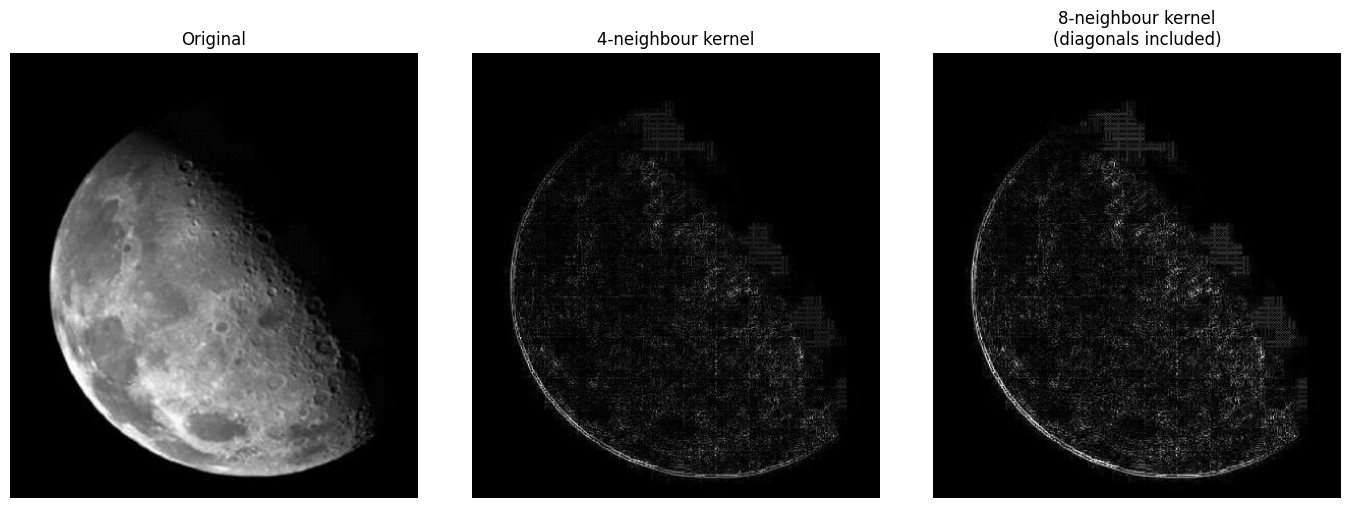

In [26]:
kernel_4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
kernel_8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float32)

lap_4 = cv2.filter2D(img, cv2.CV_64F, kernel_4)
lap_8 = cv2.filter2D(img, cv2.CV_64F, kernel_8)

print(f"{'kernel':<16}{'sum':>6}{'range':>22}{'std':>10}")
print("-" * 56)
for name, k, l in [("4-neighbour", kernel_4, lap_4), ("8-neighbour", kernel_8, lap_8)]:
    print(f"{name:<16}{k.sum():>6.0f}{f'{l.min():.0f} to {l.max():.0f}':>22}{l.std():>10.2f}")

plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(cv2.convertScaleAbs(lap_4), cmap='gray')
plt.title('4-neighbour kernel'), plt.axis('off')
plt.subplot(133), plt.imshow(cv2.convertScaleAbs(lap_8), cmap='gray')
plt.title('8-neighbour kernel\n(diagonals included)'), plt.axis('off')
plt.tight_layout()
plt.show()

### Testing the diagonal claim

The cleanest way to see what a kernel does is to feed it a **single bright pixel** on a black
background. The output is then the kernel itself, which makes the difference unambiguous.

In [27]:
impulse = np.zeros((9, 9), np.uint8)
impulse[4, 4] = 100

r4 = cv2.filter2D(impulse, cv2.CV_64F, kernel_4)
r8 = cv2.filter2D(impulse, cv2.CV_64F, kernel_8)

print("response around the bright pixel")
print("4-neighbour:"); print(r4[3:6, 3:6].astype(int))
print("8-neighbour:"); print(r8[3:6, 3:6].astype(int))
print()
print("at a DIAGONAL neighbour:  4-nb =", int(r4[3, 3]),
      "| 8-nb =", int(r8[3, 3]), " <- the whole difference, in one number")
print("at an AXIAL   neighbour:  4-nb =", int(r4[3, 4]),
      "| 8-nb =", int(r8[3, 4]), " <- identical")

response around the bright pixel
4-neighbour:
[[   0  100    0]
 [ 100 -400  100]
 [   0  100    0]]
8-neighbour:
[[ 100  100  100]
 [ 100 -800  100]
 [ 100  100  100]]

at a DIAGONAL neighbour:  4-nb = 0 | 8-nb = 100  <- the whole difference, in one number
at an AXIAL   neighbour:  4-nb = 100 | 8-nb = 100  <- identical


The 4-neighbour kernel returns **zero** at the diagonal positions: it simply does not look
there. The 8-neighbour kernel returns the same value diagonally as it does axially.

### A measurement that does *not* say what it looks like it says

The obvious follow-up is to compare the response to a diagonal step edge against a horizontal
one. That test is worth running, because its result is easy to misread.

In [28]:
yy, xx = np.mgrid[:120, :120]
diag_edge = np.zeros((120, 120), np.uint8); diag_edge[yy > xx] = 200
horz_edge = np.zeros((120, 120), np.uint8); horz_edge[60:, :] = 200

inner = (slice(10, 110), slice(10, 110))     # ignore the image border
print(f"{'edge':<18}{'4-neighbour':>14}{'8-neighbour':>14}{'ratio':>9}")
print("-" * 56)
for name, im in [("diagonal step", diag_edge), ("horizontal step", horz_edge)]:
    a = np.abs(cv2.filter2D(im, cv2.CV_64F, kernel_4))[inner].max()
    b = np.abs(cv2.filter2D(im, cv2.CV_64F, kernel_8))[inner].max()
    print(f"{name:<18}{a:>14.0f}{b:>14.0f}{b / a:>9.2f}")

edge                 4-neighbour   8-neighbour    ratio
--------------------------------------------------------
diagonal step                400           600     1.50
horizontal step              200           600     3.00


Read carelessly, this looks like the 4-neighbour kernel responds **twice as strongly** to the
diagonal edge as to the horizontal one — the opposite of what was just demonstrated.

The explanation is that a diagonal line on a square grid is not a diagonal: it is a
**staircase**. Every step is a short vertical and horizontal segment, and those are exactly
what the 4-neighbour kernel is built to detect. The test measures the staircase, not the
orientation.

This is why the impulse response is the right test: it isolates the kernel from whatever the
image happens to contain.

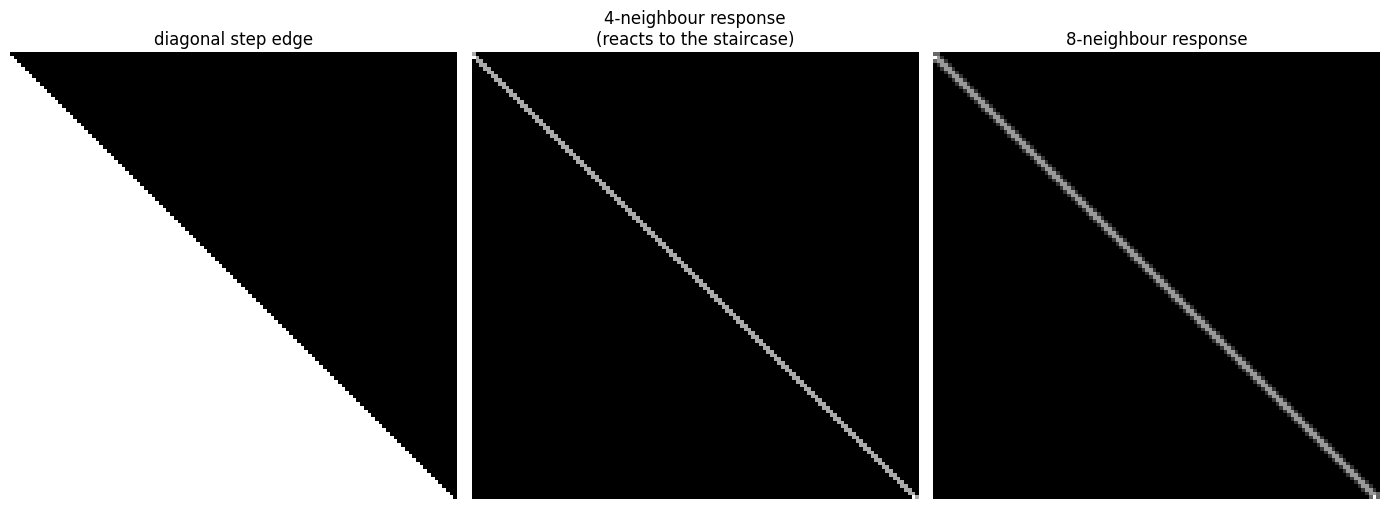

In [29]:
plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(diag_edge, cmap='gray'), plt.title('diagonal step edge'), plt.axis('off')
plt.subplot(132), plt.imshow(np.abs(cv2.filter2D(diag_edge, cv2.CV_64F, kernel_4)), cmap='gray')
plt.title('4-neighbour response\n(reacts to the staircase)'), plt.axis('off')
plt.subplot(133), plt.imshow(np.abs(cv2.filter2D(diag_edge, cv2.CV_64F, kernel_8)), cmap='gray')
plt.title('8-neighbour response'), plt.axis('off')
plt.tight_layout()
plt.show()

### Sharpening with both, and saving the results

std — original: 65.11 | 4-neighbour: 66.28 | 8-neighbour: 68.95


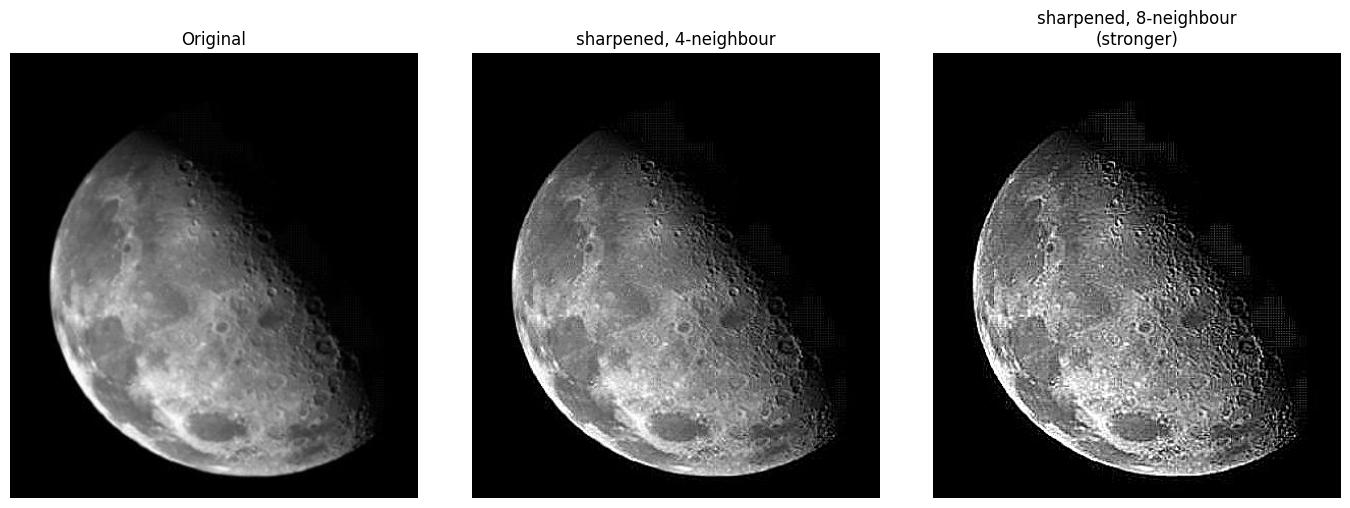

Saved: output/lab7a_laplacian.png, output/lab7a_sharpened.png


In [30]:
sharp_4 = np.clip(img.astype(np.float64) - lap_4, 0, 255).astype(np.uint8)
sharp_8 = np.clip(img.astype(np.float64) - lap_8, 0, 255).astype(np.uint8)

print("std — original:", round(float(img.std()), 2),
      "| 4-neighbour:", round(float(sharp_4.std()), 2),
      "| 8-neighbour:", round(float(sharp_8.std()), 2))

plt.figure(figsize=(14, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(sharp_4, cmap='gray')
plt.title('sharpened, 4-neighbour'), plt.axis('off')
plt.subplot(133), plt.imshow(sharp_8, cmap='gray')
plt.title('sharpened, 8-neighbour\n(stronger)'), plt.axis('off')
plt.tight_layout()
plt.show()

cv2.imwrite('output/lab7a_laplacian.png', laplacian_abs)
cv2.imwrite('output/lab7a_sharpened.png', sharpened_subtract)
print("Saved: output/lab7a_laplacian.png, output/lab7a_sharpened.png")

---
## Conclusion

The Laplacian is a second-derivative operator whose kernel sums to zero, so it returns nothing
on flat regions and responds only where the intensity changes. That single property is what
makes it both an edge detector and the basis of a sharpening filter.

**Three things in this code decide whether the result is correct.**

*The output depth must be `CV_64F`, not `-1`.* The Laplacian is negative wherever a pixel is
brighter than its neighbours, and a `uint8` output would clip every one of those values to zero.

*`img + laplacian_abs` wraps around.* Both arrays are `uint8`, so sums above 255 are taken
modulo 256 and a bright pixel plus a strong edge response comes out **dark**. The dark speckles
in the fourth panel of Part 1 are this error, not image noise, and they affect a measurable
fraction of the image. `cv2.add` saturates instead and removes them.

*The sign follows from the kernel.* With a negative centre the textbook formula is
`f - laplacian`: subtracting a negative value brightens peaks, subtracting a positive one
deepens troughs, and edges gain contrast symmetrically. The `f + abs(lap)` form used in the
given code also increases apparent sharpness, but it adds brightness at every edge and raises
the mean of the whole image.

**Two kernels, one principle.** The 4-neighbour and 8-neighbour versions both sum to zero, but
the second counts the diagonals as well. Feeding each one a single bright pixel settles the
difference in one number: the 4-neighbour kernel returns **zero** at the diagonal positions
while the 8-neighbour returns the same value it returns axially.

The step-edge measurement that followed is a useful warning. It appears to show the
4-neighbour kernel responding twice as strongly to a diagonal edge as to a horizontal one,
which contradicts the impulse test. The reason is that a diagonal line on a square grid is a
**staircase** of short vertical and horizontal segments — precisely what the 4-neighbour
kernel detects. The test measured the discretisation, not the orientation. The impulse
response is the reliable test because it isolates the kernel from the content of the image.

Finally, the Laplacian cannot distinguish an edge from a noisy pixel, so applying a small
Gaussian blur first — the Laplacian of Gaussian — keeps it from amplifying noise along with
the detail.